# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize
import scipy.stats as stats
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial import KDTree

tf.get_logger().setLevel('ERROR')
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

# Paramètres du problème

In [2]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

viscosity = tf.constant(1e-3, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.5
xmin = 0.
xmax = 1.
ymin = 0. 
ymax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin, ymin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, ymax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x, y):
    return 1.5-2.0*x

# Define boundary condition
def fun_u_b(t, x, y):
    return 1.5-2.0*x

# données d'entrainement

In [3]:
def gen_train_data(N_r=10_000, N_0=10_000, N_b=10_000):

  # Set random seed for reproducible results
  tf.random.set_seed(0)

  # Draw uniformly sampled collocation points
  t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
  x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
  y_r = tf.random.uniform((N_r,1), lb[2], ub[2], dtype=DTYPE)
  X_r = tf.concat([t_r, x_r, y_r], axis=1)

  # Draw uniform sample points for initial boundary data
  t_0 = tf.ones((N_0,1), dtype=DTYPE)*lb[0]
  x_0 = tf.random.uniform((N_0,1), lb[1], ub[1], dtype=DTYPE)
  y_0 = tf.random.uniform((N_0,1), lb[2], ub[2], dtype=DTYPE)
  X_0 = tf.concat([t_0, x_0, y_0], axis=1)

  # Evaluate intitial condition at x_0
  u_0 = fun_u_0(x_0, y_0)
    
  # Boundary data
  N_b1 = 2*N_b//3
  t_b1 = tf.random.uniform((N_b1,1), lb[0], ub[0], dtype=DTYPE)
  x_b1 = lb[1] + (ub[1] - lb[1]) * tf.keras.backend.random_bernoulli((N_b1,1), 0.5, dtype=DTYPE)
  y_b1 = tf.random.uniform((N_b1,1), lb[2], ub[2], dtype=DTYPE)
    
  N_b2 = N_b//3
  t_b2 = tf.random.uniform((N_b2,1), lb[0], ub[0], dtype=DTYPE)
  x_b2 = tf.random.uniform((N_b2,1), lb[1], ub[1], dtype=DTYPE)
  y_b2 = tf.ones((N_b2,1), dtype=DTYPE)*lb[2]

  t_b = tf.concat([t_b1, t_b2], axis=0)
  x_b = tf.concat([x_b1, x_b2], axis=0)
  y_b = tf.concat([y_b1, y_b2], axis=0)
  
  X_b = tf.concat([t_b, x_b, y_b], axis=1)

  # Evaluate boundary condition at (t_b,x_b)
  u_b = fun_u_b(t_b, x_b, y_b)

  # Collect boundary and inital data in lists
  X_data = [X_0, X_b]
  u_data = [u_0, u_b]

  return X_r, X_data, u_data

In [4]:
X_r, X_data, u_data = gen_train_data(100_000,40_000,40_000)

## PINN model

In [5]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call_before(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y
        
        
    def call(self, X):
        """Call with imposed IC/BC"""
        
        # passage dans le NN
        Y = self.call_before(X)
        return Y

        # imposer conditions au bords
        t, x, y = X[:,0:1], X[:,1:2], X[:,2:3]
        tanh_t = tf.tanh(3.1415*t)
    
        return (1-tanh_t)*fun_u_0(x, y) + x*(1-x)*y*tanh_t*Y

In [6]:
class PINNSolver():
    def __init__(self, model, batch_size):
        self.model = model
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.epoch = 0
        self.batch_size = batch_size
        self.best_loss = 1.0
        self.count_since_best_loss = 0
    
    def get_r(self, X):
        
        t = X[:,0:1]
        x = X[:,1:2]
        y = X[:,2:3]
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(t)
            tape.watch(x)
            tape.watch(y)
        
            # Compute current values u(t,x)
            u = self.model(tf.stack([t[:,0], x[:,0], y[:,0]], axis=1))
            
            u_x = tape.gradient(u, x)
            u_y = tape.gradient(u, y)
            
        u_t = tape.gradient(u, t)
        u_xx = tape.gradient(u_x, x)
        u_yy = tape.gradient(u_y, y)

        del tape
        
        return u_t + u*u_x + u_y - viscosity*(u_xx + u_yy)
    
    def loss_fn(self, X_r):
        
        # Compute phi_r
        r = self.get_r(X_r)
        phi_r = tf.reduce_mean(tf.square(r))
        
        # Initialize loss
        loss = 1e2*phi_r
        
        # Add phi_0 and phi_b to the loss
        for i in range(len(X_data)):
            u_pred = self.model(X_data[i])
            loss += tf.reduce_mean(tf.square(u_data[i] - u_pred))
        
        return loss
    
    def get_grad(self, X):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(X)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    

    def solve_with_TFoptimizer(self, optimizer, X_r, alpha):
        """This method performs a gradient descent type optimization."""
        
        self.nb_uniform  = int(alpha * self.batch_size)
        self.nb_residual = int((1-alpha) * self.batch_size)
        
        @tf.function
        def train_step(batch):
            loss, grad_theta = self.get_grad(batch)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        num_epochs = 50_000
        for epoch in range(num_epochs):
                        
        # calcul de q_i 
          J_rho = self.get_r(X_r) 
          sum_J_rho = tf.reduce_sum(J_rho**2)
          q = J_rho**2 / sum_J_rho
          q = q.numpy().flatten()
        
          for step in range(1):

              # tire les points 
              indices_uniform  = np.random.choice(len(X_r), size=self.nb_uniform, replace=False)
              indices_residual = np.random.choice(len(X_r), size=self.nb_residual, replace=False, p=q)
              indices = np.concatenate((indices_uniform, indices_residual), axis=None)
              batch = tf.gather(X_r, indices)

              # descente de gradient
              loss = train_step(batch)

          self.current_loss = self.loss_fn(X_r)
          self.callback()
            
        self.model.load_weights('best_weight-hubert.h5')
        
    def solve_with_ScipyOptimizer(self, X, method='L-BFGS-B'):
        
        def get_weight_tensor():
            """Function to return current variables of the model
            as 1d tensor as well as corresponding shapes as lists."""
            
            weight_list = []
            shape_list = []
            
            # Loop over all variables, i.e. weight matrices, bias vectors and unknown parameters
            for v in self.model.variables:
                shape_list.append(v.shape)
                weight_list.extend(v.numpy().flatten())
                
            weight_list = tf.convert_to_tensor(weight_list)
            return weight_list, shape_list

        x0, shape_list = get_weight_tensor()
        
        def set_weight_tensor(weight_list):
            """Function which sets list of weights
            to variables in the model."""
            idx = 0
            for v in self.model.variables:
                vs = v.shape
                
                # Weight matrices
                if len(vs) == 2:  
                    sw = vs[0]*vs[1]
                    new_val = tf.reshape(weight_list[idx:idx+sw],(vs[0],vs[1]))
                    idx += sw
                
                # Bias vectors
                elif len(vs) == 1:
                    new_val = weight_list[idx:idx+vs[0]]
                    idx += vs[0]
                    
                # Variables (in case of parameter identification setting)
                elif len(vs) == 0:
                    new_val = weight_list[idx]
                    idx += 1
                    
                # Assign variables (Casting necessary since scipy requires float64 type)
                v.assign(tf.cast(new_val, DTYPE))
        
        def get_loss_and_grad(w):
            """Function that provides current loss and gradient
            w.r.t the trainable variables as vector. This is mandatory
            for the LBFGS minimizer from scipy."""
            
            # Update weights in model
            set_weight_tensor(w)
            # Determine value of \phi and gradient w.r.t. \theta at w
            loss, grad = self.get_grad(X)
            
            # Store current loss for callback function            
            loss = loss.numpy().astype(np.float64)
            self.current_loss = loss            
            
            # Flatten gradient
            grad_flat = []
            for g in grad:
                grad_flat.extend(g.numpy().flatten())
            
            # Gradient list to array
            grad_flat = np.array(grad_flat,dtype=np.float64)
            
            # Return value and gradient of \phi as tuple
            return loss, grad_flat
        
        
        return scipy.optimize.minimize(fun=get_loss_and_grad,
                                       x0=x0,
                                       jac=True,
                                       method=method,
                                       callback=self.callback,
                                       options={'maxiter': 3000,
                                                'maxfun': 50000,
                                                'maxcor': 50,
                                                'maxls': 50,
                                                'ftol': 1.0*np.finfo(float).eps})

    def callback(self, xr=None):
        self.count_since_best_loss+=1
        
        if self.epoch % 100 == 0:
            print('\rEpoch {:06_}: loss = {:10.8e}'.format(self.epoch,self.current_loss), end='')
            
            if self.current_loss < self.best_loss:
                self.best_loss = self.current_loss
                self.count_since_best_loss = 0
                self.model.save_weights('best_weight-hubert2.h5')
                
            if self.count_since_best_loss == 1000:
                self.model.load_weights('best_weight-hubert2.h5')
                
            
        self.hist.append(self.current_loss)
        self.epoch+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

In [7]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=8, num_neurons_per_layer=150, activation='tanh')
solver = PINNSolver(model, batch_size = 10_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=100,
    decay_rate=0.99,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, alpha = 0.2)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 49_900: loss = 7.27972090e-02
Training time: 14399.09672999382 seconds


In [8]:
t0 = time()
try: 
  optim = tf.keras.optimizers.Adam(learning_rate=1e-5)
  solver.solve_with_TFoptimizer(optim, X_r, alpha = 0.2)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 99_900: loss = 1.30106055e-03
Training time: 14620.477429628372 seconds


In [9]:
X_r, X_data, u_data = gen_train_data(50_000,40_000,40_000)

In [10]:
#model = PhysicsInformedNN(lb, ub, num_hidden_layers=10, num_neurons_per_layer=200, activation='tanh')
#solver = PINNSolver(model, batch_size = 10_000)
#model(X_r[:10])
#model.load_weights('best_weight-hubert.h5')

t0 = time()
try: 
    solver.solve_with_ScipyOptimizer(X_r)
    solver.solve_with_ScipyOptimizer(X_r)
    solver.solve_with_ScipyOptimizer(X_r)
except:
    pass
print('\nTraining time: {} seconds'.format(time()-t0))

Epoch 102_400: loss = 1.35754701e-03
Training time: 879.4733111858368 seconds


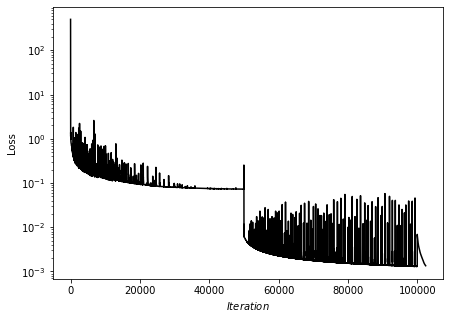

In [11]:
#model.load_weights('best_weight-hubert.h5')
solver.plot_loss_history();

# vérification que ca fonctionne 

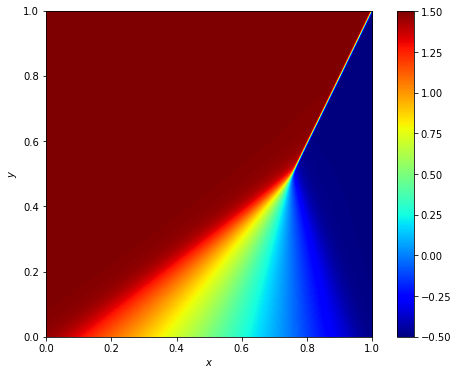

In [12]:
N = 500

# compute solution using PINN
xspace = np.linspace(0,1,N)
yspace = np.linspace(0,1,N)
tfinal =  1.5 * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

# reshape for plotting
U = upred.numpy().reshape(N,N)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(U, cmap='jet', origin='lower', extent=[0.,1.,0.,1.]);
fig.colorbar(img);

In [13]:
import requests

bot_token = '5169497350:AAHiAyn6D8q9QDoRzTC8HnQU8kYJ-M6xoDg'
bot_chatID = '1061558745'
send_text = 'https://api.telegram.org/bot' + bot_token + '/sendMessage?chat_id=' + bot_chatID + '&parse_mode=Markdown&text=' + 'Les calculs sont finito pipo ' + str(solver.best_loss)

requests.get(send_text)

<Response [200]>